# Reflector loss and laser linewidth
Two weak reflectors sit at 0.5 and 2 m. Measure each peak against its own lossless reference. This cancels the frequency response of the detector and transmission through the first reflector. The first experiment changes fibre attenuation, the second changes laser linewidth.

In [1]:
from copy import deepcopy
import numpy as np
import matplotlib.pyplot as plt

from pyofdr.core.config import load_config
from pyofdr.core.campaign import run_campaign
from pyofdr.analysis.demodulation import reflectogram_from_acq
from pyofdr.analysis.spatial_metrics import measure_resolution
from pyofdr.utils.constants import C

cfg = load_config('../configs/ofdr_basic.yaml')
positions = [0.5, 2.0]
cfg['fiber'].update(length=2.5, attenuation_dB_per_km=0, rayleigh_coefficient_dB=-150,
                    reflectors=[{'z': z, 'R': 1e-3} for z in positions])
cfg['source'].update(sweep_range=4e-9, sweep_duration=0.002, linewidth=0)
cfg['adc']['sample_rate'] = 50e6
cfg['detection'].update(shot_noise=False, thermal_nep=0, dark_current=0)

def peaks(alpha=0, linewidth=0):
    trial = deepcopy(cfg)
    trial['fiber']['attenuation_dB_per_km'] = alpha
    trial['source']['linewidth'] = linewidth
    acq = run_campaign(trial)[0]
    H, z = reflectogram_from_acq(acq, window='hanning', n_pad=4 * acq.n_samples)
    return [measure_resolution(H, z, p) for p in positions]

reference = peaks()
for p, m in zip(positions, reference):
    print(f"Configured {p:.4f} m, measured {m['peak_z']:.4f} m")

Configured 0.5000 m, measured 0.4999 m
Configured 2.0000 m, measured 2.0000 m


## Round-trip loss
With one-way attenuation $\alpha$ in dB/km, the expected change in peak level is $-2\alpha z/1000$ dB for $z$ in metres. Use a deliberately large attenuation so the difference is visible over this short fibre.

In [2]:
alpha = 200.0
lossy = peaks(alpha=alpha)
for base, m in zip(reference, lossy):
    expected = -2 * alpha * base['peak_z'] / 1000
    measured = m['peak_dB'] - base['peak_dB']
    print(f"{base['peak_z']:.3f} m: measured {measured:.3f} dB, expected {expected:.3f} dB")

0.500 m: measured -0.200 dB, expected -0.200 dB
2.000 m: measured -0.800 dB, expected -0.800 dB


## Linewidth sweep
The main interferometer models white FM through the coherence factor $\exp(-\pi\,\Delta\nu\,2nz/c)$ in beat amplitude. A single reflector should lose peak height as linewidth grows. Its width at −6 dB is set by the sweep and FFT window in this experiment. Compare width and height separately.

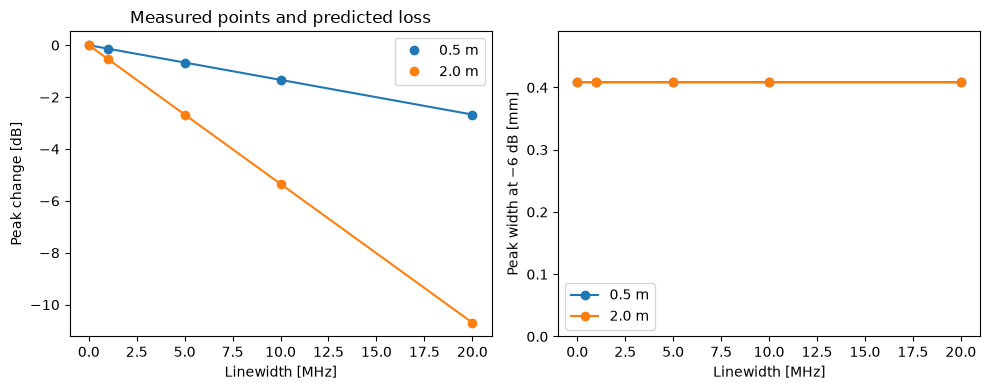

In [3]:
widths_hz = np.array([0, 1e6, 5e6, 10e6, 20e6])
runs = [reference] + [peaks(linewidth=w) for w in widths_hz[1:]]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for i, base in enumerate(reference):
    tau = 2 * cfg['fiber']['n_core'] * base['peak_z'] / C
    prediction = -20 * np.pi * widths_hz * tau / np.log(10)
    levels = [run[i]['peak_dB'] - base['peak_dB'] for run in runs]
    widths = [1e3 * run[i]['resolution'] for run in runs]
    label = f"{base['peak_z']:.1f} m"
    line, = ax1.plot(widths_hz / 1e6, levels, 'o', label=label)
    ax1.plot(widths_hz / 1e6, prediction, color=line.get_color())
    ax2.plot(widths_hz / 1e6, widths, 'o-', label=label)
ax1.set(xlabel='Linewidth [MHz]', ylabel='Peak change [dB]', title='Measured points and predicted loss')
ax2.set(xlabel='Linewidth [MHz]', ylabel='Peak width at −6 dB [mm]')
ax2.set_ylim(0, 1.2 * ax2.get_ylim()[1])
for ax in (ax1, ax2):
    ax.legend()
fig.tight_layout()
plt.show()